In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt
import time
import os

from torch.utils.data import TensorDataset, DataLoader

In [2]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [3]:
# MNIST folder path from your screenshot
path = r"C:\Users\KUNAL\Downloads\Dataset_DL\Dataset_DL\MNIST"

# Function to load images
def load_images(filename):

    file_path = os.path.join(path, filename)

    with open(file_path, "rb") as f:

        data = np.fromfile(f, dtype=np.uint8)

    # First 16 bytes contain the image header
    images = data[16:].reshape(-1, 28, 28)

    return images


# Function to load labels
def load_labels(filename):

    file_path = os.path.join(path, filename)

    with open(file_path, "rb") as f:

        data = np.fromfile(f, dtype=np.uint8)

    # First 8 bytes contain the label header
    labels = data[8:]

    return labels


# Load training data
X_train = load_images("train-images-idx3-ubyte")
y_train = load_labels("train-labels-idx1-ubyte")

# Load testing data
X_test = load_images("t10k-images-idx3-ubyte")
y_test = load_labels("t10k-labels-idx1-ubyte")


# Convert into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32) / 255.0
y_train = torch.tensor(y_train, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32) / 255.0
y_test = torch.tensor(y_test, dtype=torch.long)


# Reshape images into 1 channel, 28 x 28
X_train = X_train.unsqueeze(1)
X_test = X_test.unsqueeze(1)


# Create datasets
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_test, y_test)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)


print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Dataset loaded successfully!")

Training samples: 60000
Validation samples: 10000
Dataset loaded successfully!


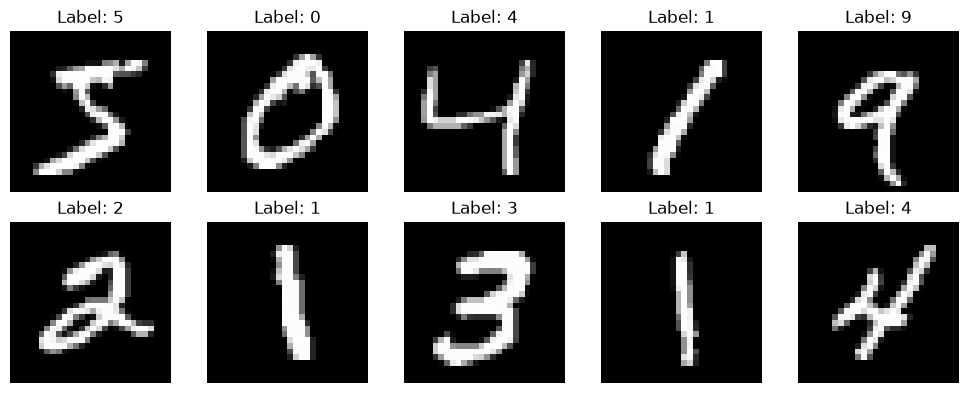

In [4]:
plt.figure(figsize=(10, 4))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i][0], cmap="gray")

    plt.title(f"Label: {y_train[i].item()}")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
class MLP(nn.Module):

    def __init__(self, activation):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

        self.activation = activation

    def forward(self, x):

        x = self.flatten(x)

        x = self.activation(self.fc1(x))

        x = self.activation(self.fc2(x))

        x = self.fc3(x)

        return x

In [6]:
def train_model(activation, epochs=10):

    model = MLP(activation).to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.CrossEntropyLoss()

    train_losses = []
    val_accuracies = []

    gradient_norms = {
        "fc1": [],
        "fc2": [],
        "fc3": []
    }

    epoch_times = []

    for epoch in range(epochs):

        start_time = time.time()

        model.train()

        running_loss = 0.0

        layer_gradients = {
            "fc1": 0.0,
            "fc2": 0.0,
            "fc3": 0.0
        }

        num_batches = 0

        # Training
        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            # Calculate gradients of each layer
            for name, layer in [
                ("fc1", model.fc1),
                ("fc2", model.fc2),
                ("fc3", model.fc3)
            ]:

                total_grad = 0.0

                for param in layer.parameters():

                    if param.grad is not None:
                        total_grad += param.grad.norm(2).item()

                layer_gradients[name] += total_grad

            optimizer.step()

            running_loss += loss.item()

            num_batches += 1

        # Average training loss
        epoch_loss = running_loss / len(train_loader)

        train_losses.append(epoch_loss)

        # Average gradient for each layer
        for name in layer_gradients:

            avg_grad = layer_gradients[name] / num_batches

            gradient_norms[name].append(avg_grad)

        # Calculate training time
        if device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.time() - start_time

        epoch_times.append(epoch_time)

        # Validation
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)

                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total

        val_accuracies.append(accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Val Accuracy: {accuracy:.2f}% "
            f"Time: {epoch_time:.2f}s"
        )

    total_time = sum(epoch_times)

    print("Total Training Time:", round(total_time, 2), "seconds")

    return train_losses, val_accuracies, gradient_norms, epoch_times

In [7]:
results = {}

activations = {
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "ReLU": nn.ReLU()
}

for name, activation in activations.items():

    print("\n" + "=" * 50)
    print("Training MLP with", name)
    print("=" * 50)

    loss, accuracy, gradients, times = train_model(
        activation,
        epochs=10
    )

    results[name] = {
        "loss": loss,
        "accuracy": accuracy,
        "gradient": gradients,
        "time": times
    }


Training MLP with Sigmoid
Epoch [1/10] Loss: 0.7122 Val Accuracy: 91.99% Time: 7.47s
Epoch [2/10] Loss: 0.2325 Val Accuracy: 94.37% Time: 7.99s
Epoch [3/10] Loss: 0.1684 Val Accuracy: 95.58% Time: 7.78s
Epoch [4/10] Loss: 0.1310 Val Accuracy: 96.00% Time: 5.58s
Epoch [5/10] Loss: 0.1050 Val Accuracy: 96.84% Time: 5.94s
Epoch [6/10] Loss: 0.0851 Val Accuracy: 97.00% Time: 5.54s
Epoch [7/10] Loss: 0.0704 Val Accuracy: 97.27% Time: 5.50s
Epoch [8/10] Loss: 0.0577 Val Accuracy: 97.52% Time: 5.61s
Epoch [9/10] Loss: 0.0488 Val Accuracy: 97.57% Time: 5.84s
Epoch [10/10] Loss: 0.0401 Val Accuracy: 97.61% Time: 5.78s
Total Training Time: 63.02 seconds

Training MLP with Tanh
Epoch [1/10] Loss: 0.3389 Val Accuracy: 94.70% Time: 6.10s
Epoch [2/10] Loss: 0.1524 Val Accuracy: 95.78% Time: 5.74s
Epoch [3/10] Loss: 0.1036 Val Accuracy: 96.56% Time: 6.83s
Epoch [4/10] Loss: 0.0774 Val Accuracy: 97.55% Time: 6.32s
Epoch [5/10] Loss: 0.0577 Val Accuracy: 97.64% Time: 6.22s
Epoch [6/10] Loss: 0.0442 Va

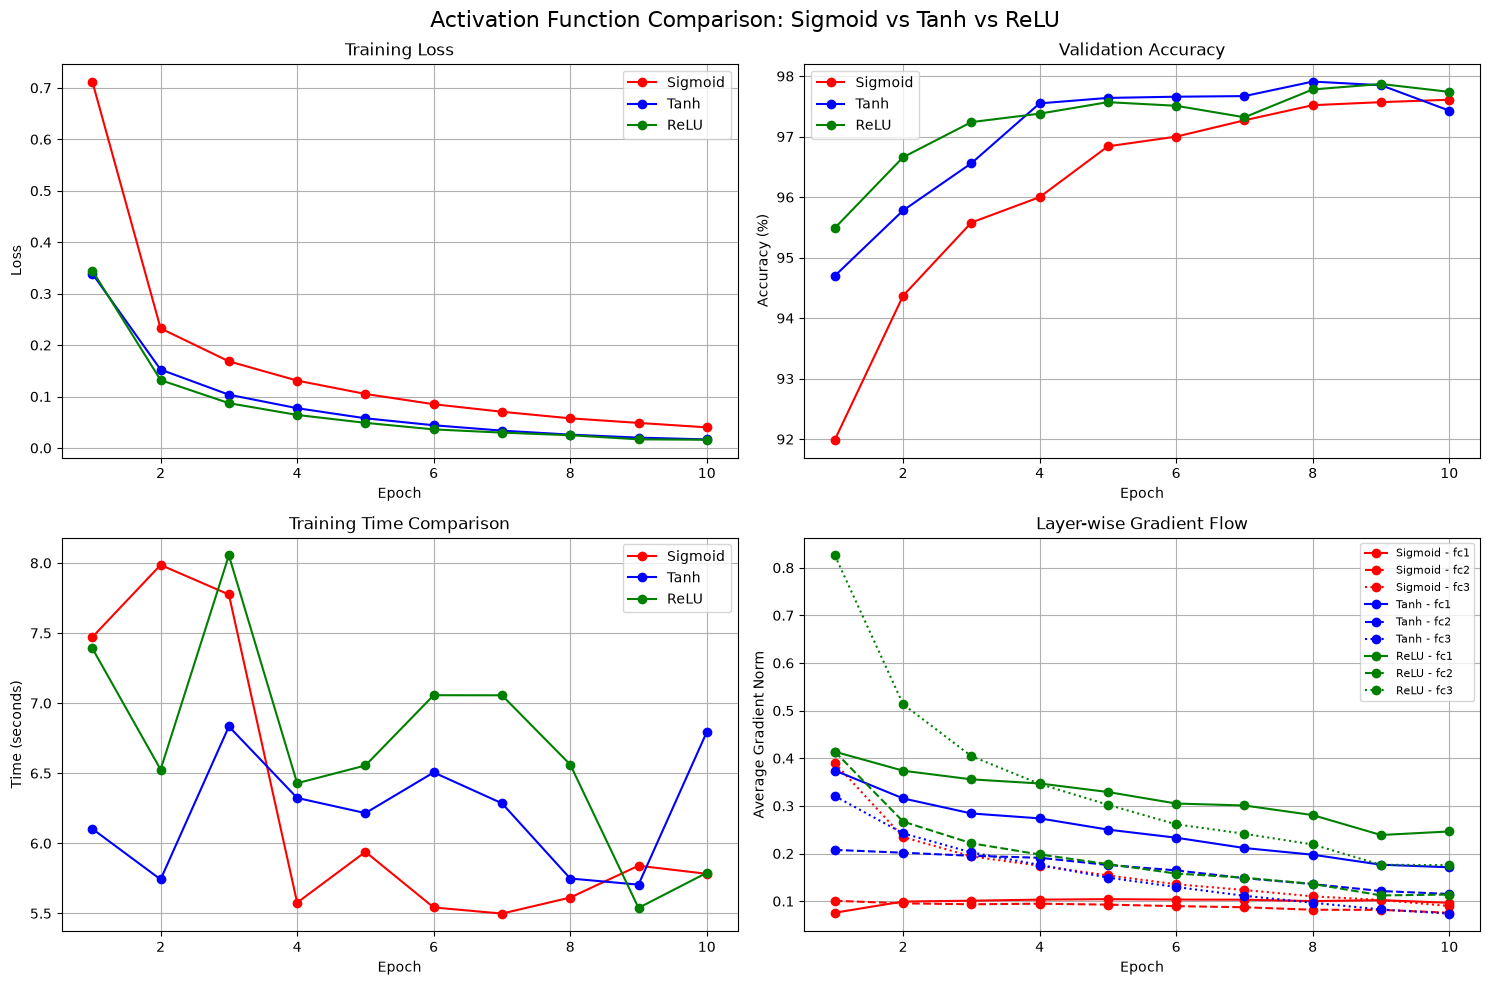

In [8]:
epochs = range(1, 11)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

colors = {
    "Sigmoid": "red",
    "Tanh": "blue",
    "ReLU": "green"
}

# 1. Training Loss
for name in activations:

    axes[0, 0].plot(
        epochs,
        results[name]["loss"],
        color=colors[name],
        marker="o",
        label=name
    )

axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)


# 2. Validation Accuracy
for name in activations:

    axes[0, 1].plot(
        epochs,
        results[name]["accuracy"],
        color=colors[name],
        marker="o",
        label=name
    )

axes[0, 1].set_title("Validation Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy (%)")
axes[0, 1].legend()
axes[0, 1].grid(True)


# 3. Training Time
for name in activations:

    axes[1, 0].plot(
        epochs,
        results[name]["time"],
        color=colors[name],
        marker="o",
        label=name
    )

axes[1, 0].set_title("Training Time Comparison")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Time (seconds)")
axes[1, 0].legend()
axes[1, 0].grid(True)


# 4. Layer-wise Gradient Flow
linestyles = {
    "fc1": "-",
    "fc2": "--",
    "fc3": ":"
}

for name in activations:

    for layer in ["fc1", "fc2", "fc3"]:

        axes[1, 1].plot(
            epochs,
            results[name]["gradient"][layer],
            color=colors[name],
            linestyle=linestyles[layer],
            marker="o",
            label=f"{name} - {layer}"
        )

axes[1, 1].set_title("Layer-wise Gradient Flow")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Average Gradient Norm")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True)

plt.suptitle(
    "Activation Function Comparison: Sigmoid vs Tanh vs ReLU",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [10]:
print("\nFINAL MODEL COMPARISON")

for name in activations:

    accuracy = results[name]["accuracy"][-1]
    total_time = sum(results[name]["time"])

    print("\nActivation:", name)
    print("Accuracy:", round(accuracy, 2), "%")
    print("Training Time:", round(total_time, 2), "seconds")


FINAL MODEL COMPARISON

Activation: Sigmoid
Accuracy: 97.61 %
Training Time: 63.02 seconds

Activation: Tanh
Accuracy: 97.43 %
Training Time: 62.26 seconds

Activation: ReLU
Accuracy: 97.74 %
Training Time: 66.96 seconds
